# 16 · Design pattern 3: parallelization
Level L3 · Part 3 · core · ~25 min · builds on 15

## Goal
Run several independent checks on the same reply at the same time, then combine their answers with a rule. This is the **voting** form of
parallelization: each reviewer answers the same question, so the answers can be compared. The fan-out is `Send`; the join waits for every
reviewer and then applies the rule.

## Why it matters
One reviewer makes one kind of mistake. A reviewer that checks the facts misses a promise; one that checks the promise misses a wrong number.
Running them one after another makes the reply wait for each in turn. Running them together costs the same calls and takes the time of the
slowest one.

| One reviewer, in turn | Three reviewers, in parallel |
|---|---|
| The reply waits for each check in turn | The reply waits for the slowest check |
| One kind of mistake is caught | Each reviewer catches a different kind |
| The answer is one opinion | A rule combines the votes, and a split vote goes to a person |

**What it makes easy:** a faster check with more kinds of mistake caught. **When you don't need it:** a reply that one check covers, or
checks that depend on each other's answers (those are a chain).

## The idea
**Parallelization** is a fan-out and a join. The fan-out sends the same input to several branches, which run at the same time. The join
waits for all of them, and a reducer keeps every answer. The rule that combines the answers is code, so it is easy to read and to test.

## Picture
`show_mermaid` is a course helper (in `graph_view.py`) that draws a diagram written as Mermaid text. It calls no model.

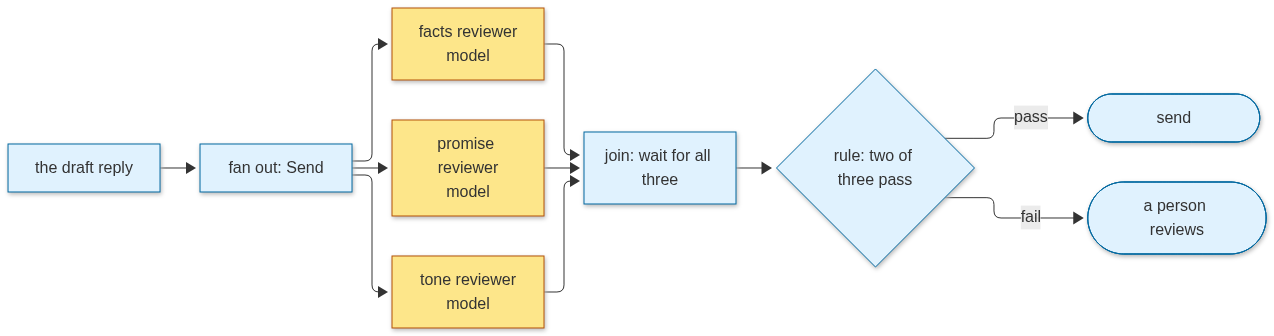

In [1]:
import sys; sys.path.insert(0, "../../..")  # makes the topic folder importable (llm_setup, graph_view, tut_env)

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  D["the draft reply"] --> F1["fan out: Send"]
  F1 --> R1["facts reviewer<br/>model"]
  F1 --> R2["promise reviewer<br/>model"]
  F1 --> R3["tone reviewer<br/>model"]
  R1 --> J["join: wait for all three"]
  R2 --> J
  R3 --> J
  J --> V{"rule: two of three pass"}
  V -->|pass| S(["send"])
  V -->|fail| H(["a person reviews"])
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class R1,R2,R3 model
  class D,F1,J,V,S,H code
""")

## Step by step
**Step 1 · setup (one model for the lesson).** Three course helpers appear here, each explained once. `llm_replay` saves the model's
answers the first time they run and replays them offline, so the lesson runs with no key. `get_llm()` returns the course model, set up in
`llm_setup.py`; its key is read from `.env`, never typed here. `show_graph` (from `graph_view.py`) draws a compiled graph.

In [2]:
import llm_replay
llm_replay.start("16_parallelization")

import operator
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel
from llm_setup import get_llm
from graph_view import show_graph

llm = get_llm()
ORDER_FACTS = {"1003": {"status": "lost", "days_late": 9, "total": 89.5}}  # the facts the reviewers may check against

LLM mode: replay (16_parallelization.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · three reviewers, each with one question (no call yet).** Each reviewer answers `pass` or `fail` and says why, in a schema the
code reads (`Review`, a pydantic model). The three questions are different on purpose: the facts, the promises and the tone.

In [3]:
class Review(BaseModel):
    verdict: Literal["pass", "fail"]
    why: str


REVIEWERS = {
    "facts": "Check that every number and status in the reply matches these facts, and that no fact is added: {facts}.",
    "promises": "Check that the reply does not promise a refund, a replacement or a date. Only a person may approve those.",
    "tone": "Check that the reply is warm, apologetic where needed, and does not blame the customer.",
}
print(Review(verdict="pass", why="checked").model_dump())  # the shape every reviewer answer takes

{'verdict': 'pass', 'why': 'checked'}


**Step 3 · the shared state and the fan-out (no call yet).** The state holds the reply, the votes and the outcome. The `votes` key has a
reducer (`operator.add`), which keeps every reviewer's answer instead of overwriting the last one. `fan_out` returns one `Send` per reviewer.

In [4]:
class ReviewState(TypedDict):
    reply: str
    votes: Annotated[list, operator.add]  # the reducer keeps every reviewer's answer
    outcome: str


def fan_out(state: ReviewState) -> list[Send]:
    return [Send("review", {"reply": state["reply"], "name": name, "question": q}) for name, q in REVIEWERS.items()]


print([s.arg["name"] for s in fan_out({"reply": "", "votes": [], "outcome": ""})])  # one branch per reviewer

['facts', 'promises', 'tone']


**Step 4 · one reviewer and the join rule (no call yet).** `review` asks the model one question. `join` runs after every branch has
answered, counts the passes and applies the rule: two of three must pass. Each reviewer waits a fixed half second more than the one
before it, so the calls start in the same order every run. The calls still overlap. The saved answers (see `llm_replay`) are handed back in
the order the calls arrive, so this order keeps every answer with its own question.

In [5]:
import time


def review(inp: dict) -> dict:
    time.sleep(0.5 * list(REVIEWERS).index(inp["name"]))  # a fixed start order: facts, promises, tone
    question = inp["question"].format(facts=ORDER_FACTS)
    result = llm.with_structured_output(Review).invoke(f"{question}\n\nReply: {inp['reply']}")
    return {"votes": [{"reviewer": inp["name"], "verdict": result.verdict, "why": result.why}]}


def join(state: ReviewState) -> dict:
    passed = sum(v["verdict"] == "pass" for v in state["votes"])
    return {"outcome": "send" if passed >= 2 else "person"}  # the rule: two of three must pass


print(join({"votes": [{"verdict": "fail"}, {"verdict": "fail"}, {"verdict": "pass"}]}))  # the rule on hand-made votes

{'outcome': 'person'}


**Step 5 · the graph: fan out, review in parallel, join, decide (3 model calls, overlapping).** The three reviewers start half a second
apart and their calls overlap. The join runs only after all three answers are in. A split vote goes to a person.

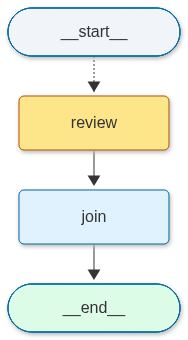

    facts: fail · The reply includes extra information about a refund and apology that was not present in the provided
 promises: fail · The reply promises a refund and provides a specific date for when the funds will reach the card, whi
     tone: pass · The reply is professional, apologetic, takes responsibility for the issue without blaming the custom
outcome: person


In [6]:
g = StateGraph(ReviewState)
g.add_node("review", review)
g.add_node("join", join)
g.add_conditional_edges(START, fan_out, ["review"])  # the fan-out
g.add_edge("review", "join").add_edge("join", END)
parallel_app = g.compile()
show_graph(parallel_app, model_nodes=("review",))

DRAFT = ("Order 1003 is lost and is 9 days late. I have refunded the 89.50 you paid, "
         "and it will reach your card tomorrow. I am sorry for the wait.")
out = parallel_app.invoke({"reply": DRAFT, "votes": [], "outcome": ""})
for v in out["votes"]:
    print(f"{v['reviewer']:>9}: {v['verdict']} · {v['why'][:100]}")
print("outcome:", out["outcome"])
llm_replay.stop()  # saves the recording: the last model call of this lesson

## At work
- Teams run a safety check and a quality check on the same reply in parallel, so the reply is not slower for having both → lesson 34
  (security and guardrails).
- A vote needs a rule written in advance. Teams decide what a split means before they see the votes, and a split goes to a person.
- Parallel calls cost the same as serial ones; they save time, not money. Count the calls, and cap the branches → lesson 36 (cost and latency).

## What just happened
- The facts reviewer said **fail**: the reply includes extra information about a refund that the order facts do not contain.
- The promises reviewer said **fail**: the draft promises a refund and a date.
- The tone reviewer said **pass**: the draft is warm and apologetic.
- Only **1 of 3** passed. The rule needs 2, so the outcome is **person**, and the wrong promise never reaches the customer.

## Common mistakes
1. **Parallel branches that depend on each other.** If one reviewer needs another's answer, the branches are a chain, not a fan-out.
2. **A join with no rule.** Without a written rule, nobody can say what a split vote means. Write the rule first, then the graph.
3. **Shared state without a reducer.** Two branches that write one key in the same step fail. The `votes` reducer keeps every answer.

The third mistake, with a tiny graph and no model call. The error is caught and printed so the lesson keeps running:

In [7]:
class PlainState(TypedDict):
    votes: list  # no reducer: two branches writing this key in one step is an error


bad = StateGraph(PlainState)
bad.add_node("review", lambda inp: {"votes": [{"verdict": inp["name"]}]})
bad.add_conditional_edges(START, lambda s: [Send("review", {"name": n}) for n in ("facts", "tone")], ["review"])
bad.add_edge("review", END)
try:
    bad.compile().invoke({"votes": []})
except Exception as err:
    print(type(err).__name__, "-", str(err).splitlines()[0])

InvalidUpdateError - At key 'votes': Can receive only one value per step. Use an Annotated key to handle multiple values.


## Try it
Write `combine(verdicts, needed)` that returns `"send"` when at least `needed` of the verdicts are `"pass"`, and `"person"` otherwise.
Test it on `["pass", "fail", "pass"]` with `needed=2`, and on `["fail", "fail", "pass"]` with `needed=2`. No model call is needed.

In [8]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [9]:
def combine(verdicts: list[str], needed: int) -> str:
    return "send" if verdicts.count("pass") >= needed else "person"


print(combine(["pass", "fail", "pass"], 2), combine(["fail", "fail", "pass"], 2))  # send person

send person


## Key terms
- **Parallelization** — running independent branches at the same time, then combining their answers.
- **Fan-out** — sending the same input to several branches (here, `Send` once per reviewer).
- **Join** — the step that waits for every branch before it continues.
- **Reducer** — the rule that merges several writes to one state key (here, `operator.add` keeps every vote).
- **Voting** — several reviewers answer the same question and a rule combines their verdicts.

## Recap
- Parallelization sends one input to several branches at the same time, and joins their answers.
- The fan-out is `Send`, and a reducer keeps every answer. The join waits for all of them.
- The rule that combines the answers is written in advance, and a split goes to a person.

**Interview:** "How do you check an agent's reply before it goes out, without making it slow?" Strong answer: "I run the independent checks in
parallel on the same draft, each checking one kind of mistake. A join applies a rule I wrote in advance, and a split vote goes to a person."